In [1]:
# DBSCAN - Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("DBSCAN Libraries Imported Successfully!")

DBSCAN Libraries Imported Successfully!


In [3]:
# DBSCAN - Load Dataset

df = pd.read_csv("segmentation data.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [4]:
print("\nFirst 5 Rows:")
print(df.head())


First 5 Rows:
          ID  Sex  Marital status  Age  Education  Income  Occupation  \
0  100000001    0               0   67          2  124670           1   
1  100000002    1               1   22          1  150773           1   
2  100000003    0               0   49          1   89210           0   
3  100000004    0               0   45          1  171565           1   
4  100000005    0               0   53          1  149031           1   

   Settlement size  
0                2  
1                2  
2                0  
3                1  
4                1  


In [5]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(2000, 8)


In [6]:
# DBSCAN - Feature Selection

X = df[['Age', 'Income']]

print("Selected Features:")
print(X.head())

Selected Features:
   Age  Income
0   67  124670
1   22  150773
2   49   89210
3   45  171565
4   53  149031


In [7]:
print("\nFeature Shape:")
print(X.shape)


Feature Shape:
(2000, 2)


In [8]:
# DBSCAN - Feature Scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed Successfully!")

print("\nScaled Data (First 5 Rows):")
print(X_scaled[:5])

Feature Scaling Completed Successfully!

Scaled Data (First 5 Rows):
[[ 2.65361447  0.09752361]
 [-1.18713209  0.78265438]
 [ 1.11731585 -0.83320224]
 [ 0.77591616  1.32838624]
 [ 1.45871554  0.73693175]]


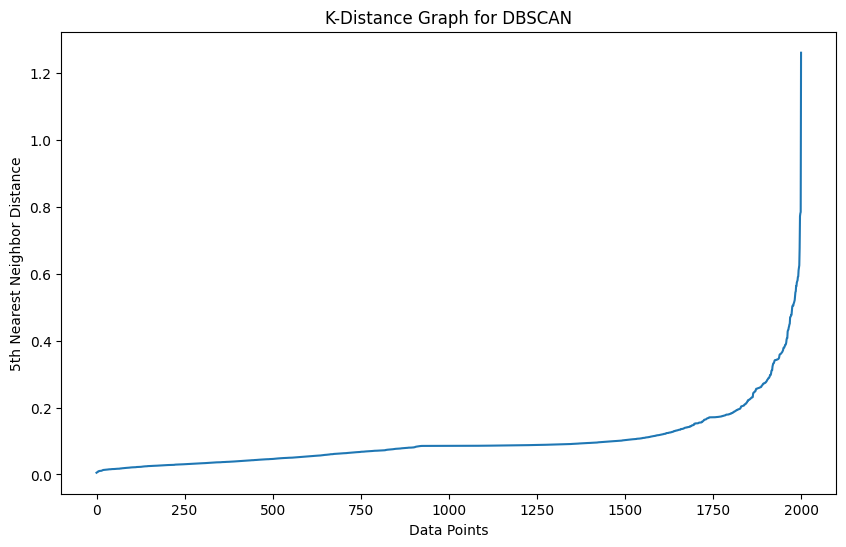

In [9]:
# DBSCAN - K-Distance Graph

from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize=(10, 6))

plt.plot(distances)

plt.title("K-Distance Graph for DBSCAN")
plt.xlabel("Data Points")
plt.ylabel("5th Nearest Neighbor Distance")

plt.show()

In [10]:
# DBSCAN Clustering Model

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN Model Created Successfully!")

DBSCAN Model Created Successfully!


In [11]:
# Cluster Distribution

df['DBSCAN_Cluster'] = dbscan_labels

print(df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    1960
 2      10
-1      10
 1       8
 3       7
 4       5
Name: count, dtype: int64


In [12]:
# DBSCAN Cluster Analysis

unique_labels = set(dbscan_labels)

n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

n_noise = list(dbscan_labels).count(-1)

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

Number of Clusters: 5
Number of Noise Points: 10


In [15]:
from sklearn.decomposition import PCA

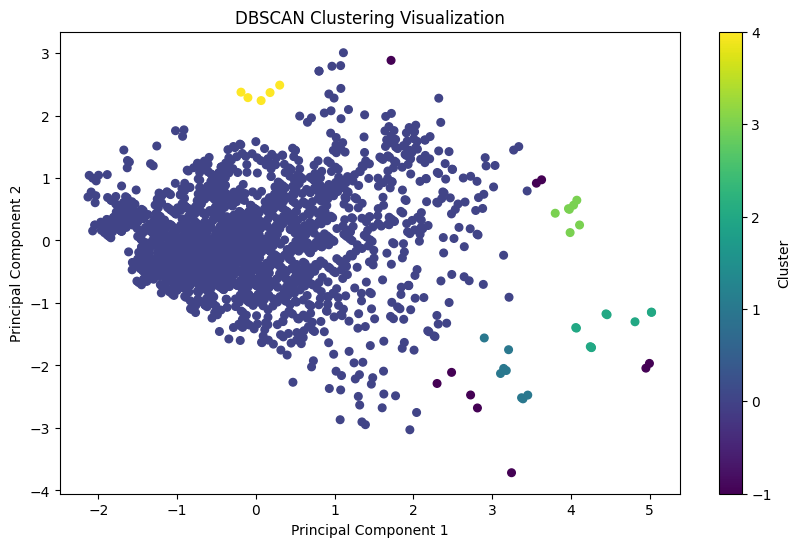

In [16]:
# DBSCAN Cluster Visualization using PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='viridis',
    s=30
)

plt.title("DBSCAN Clustering Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(label="Cluster")

plt.show()

In [17]:
# DBSCAN - Silhouette Score

from sklearn.metrics import silhouette_score

if len(set(dbscan_labels)) > 1 and len(set(dbscan_labels)) < len(dbscan_labels):

    score = silhouette_score(X_scaled, dbscan_labels)

    print("DBSCAN Silhouette Score:", score)

else:
    print("Silhouette Score cannot be calculated.")

DBSCAN Silhouette Score: 0.30184126257148797


In [18]:
# DBSCAN - Davies-Bouldin Score

from sklearn.metrics import davies_bouldin_score

if len(set(dbscan_labels)) > 1 and -1 not in dbscan_labels:

    db_score = davies_bouldin_score(X_scaled, dbscan_labels)

    print("DBSCAN Davies-Bouldin Score:", db_score)

else:
    print("Davies-Bouldin Score cannot be calculated reliably.")

Davies-Bouldin Score cannot be calculated reliably.


In [19]:
# DBSCAN - Final Cluster Summary

cluster_summary = df.groupby('DBSCAN_Cluster').size().reset_index(name='Number of Customers')

print("DBSCAN Cluster Summary:")
print(cluster_summary)

print("\nTotal Customers:", len(df))
print("Total Clusters:", n_clusters)
print("Total Noise Points:", n_noise)

DBSCAN Cluster Summary:
   DBSCAN_Cluster  Number of Customers
0              -1                   10
1               0                 1960
2               1                    8
3               2                   10
4               3                    7
5               4                    5

Total Customers: 2000
Total Clusters: 5
Total Noise Points: 10


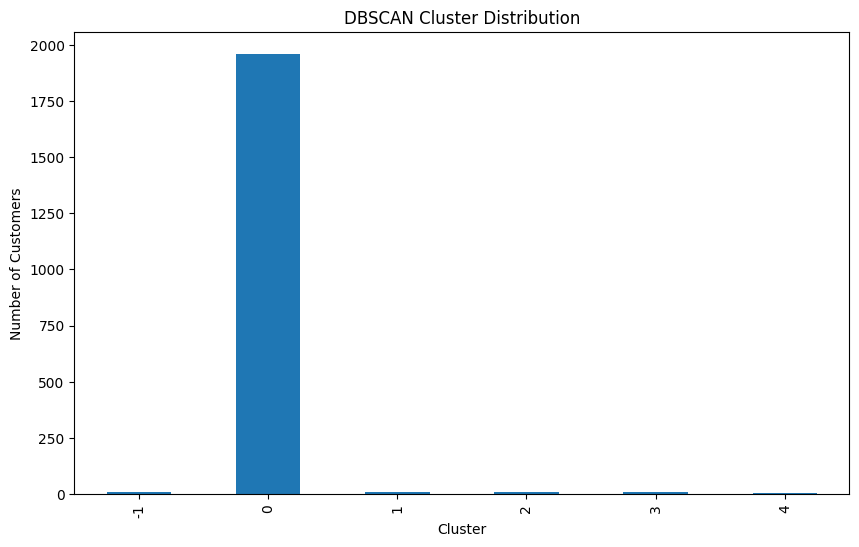

In [20]:
# DBSCAN - Cluster Distribution

plt.figure(figsize=(10, 6))

df['DBSCAN_Cluster'].value_counts().sort_index().plot(
    kind='bar'
)

plt.title("DBSCAN Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [21]:
# Save DBSCAN Results

df.to_csv("DBSCAN_Clustering_Results.csv", index=False)

print("DBSCAN Results Saved Successfully!")

DBSCAN Results Saved Successfully!


In [25]:
# Comparison of K-Means, Hierarchical and DBSCAN

from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd

comparison_results = []

# K-Means Evaluation
kmeans_score = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)

comparison_results.append({
    'Algorithm': 'K-Means',
    'Number of Clusters': len(set(kmeans_labels)),
    'Silhouette Score': kmeans_score,
    'Davies-Bouldin Score': kmeans_db
})


# Hierarchical Clustering Evaluation
hierarchical_score = silhouette_score(X_scaled, hierarchical_labels)
hierarchical_db = davies_bouldin_score(X_scaled, hierarchical_labels)

comparison_results.append({
    'Algorithm': 'Hierarchical',
    'Number of Clusters': len(set(hierarchical_labels)),
    'Silhouette Score': hierarchical_score,
    'Davies-Bouldin Score': hierarchical_db
})


# DBSCAN Evaluation (excluding noise points)
mask = dbscan_labels != -1

dbscan_valid_labels = dbscan_labels[mask]

if len(set(dbscan_valid_labels)) > 1:

    dbscan_score = silhouette_score(
        X_scaled[mask],
        dbscan_valid_labels
    )

    dbscan_db = davies_bouldin_score(
        X_scaled[mask],
        dbscan_valid_labels
    )

else:
    dbscan_score = None
    dbscan_db = None


comparison_results.append({
    'Algorithm': 'DBSCAN',
    'Number of Clusters': len(set(dbscan_labels) - {-1}),
    'Silhouette Score': dbscan_score,
    'Davies-Bouldin Score': dbscan_db
})


# Create Comparison DataFrame
comparison = pd.DataFrame(comparison_results)

print("CLUSTERING ALGORITHM COMPARISON")
print(comparison)

NameError: name 'kmeans_labels' is not defined